# Functional & Noisy Signal Population


In [26]:
import numpy as np 
import matplotlib.pyplot as plt

In [27]:
# Apply clean visual style to plots
plt.style.use('seaborn-whitegrid' if 'seaborn-whitegrid' in plt.style.available else 'default')

#run time configuration for visualization

plt.rcParams['figure.dpi'] = 100


#reproducible stichastic generation through seed set

np.random.seed(seed=42) #set the seed for reproducibility

Harmonic signal with Gaussian noise generated successfully.
Time Domain Array Length:  200
Pure Signal Array Range:  {np.float64(-2.9999065406824688)} to {np.float64(2.9999065406824688)}
Noisy Signal Array Range:  {np.float64(-4.1175790075750776)} to {np.float64(3.8821580615060465)}
Calculated noise variance:  {np.float64(0.31047640152484013)}


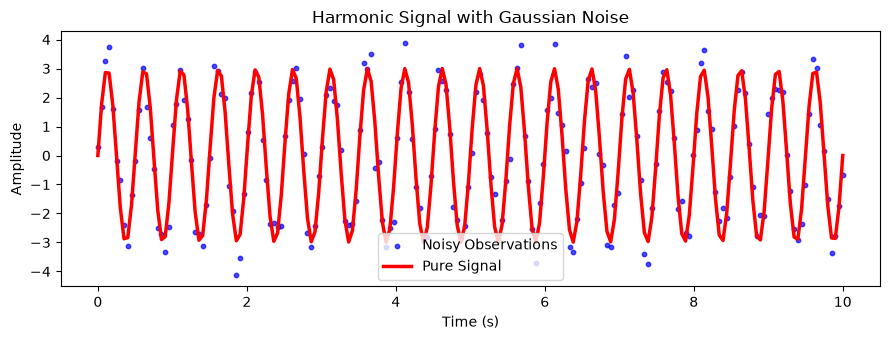

In [28]:
t=np.linspace(
    start =0, #start time
    stop = 10, #stop time
    num = 200 # number of points
)

f=2.0 #frequency of the signal
a=3.0 #amplitude of the signal

#generate the clean sinusoidal signal

y_pure=a*np.sin(2*np.pi*f*t) #pure signal

# add gaussian noise to the signal
gaussian_noise = np.random.normal(
    loc=0.0, #mean of the noise
    scale=.6, #standard deviation of the noise
    size=len(t) #size of the noise array
)

# generate the noisy signal by adding the noise to the pure signal

y_noisy = y_pure + gaussian_noise

print("Harmonic signal with Gaussian noise generated successfully.")
print("Time Domain Array Length: ", len(t))
print(f"Pure Signal Array Range: " ,{y_pure.min()} ,"to", {y_pure.max()})
print(f"Noisy Signal Array Range: " ,{y_noisy.min()} ,"to", {y_noisy.max()})
print(f"Calculated noise variance: " ,{np.var(gaussian_noise)})

plt.figure(figsize=(9, 3.5))

#noisy observations (scatter plot)

plt.scatter(
    x=t, #time array    
    y=y_noisy, #noisy signal array
    color='blue', #color of the points
    alpha=0.7, #transparency of the points
    zorder=2, #layering order of the points
    label='Noisy Observations', #label for the legend
    s=10
)

plt.plot(
    t, #time array
    y_pure, #pure signal array
    color='red', #color of the line
    linewidth=2.5, #width of the line
    zorder=3, #layering order of the line
    label='Pure Signal' #label for the legend
)

plt.title('Harmonic Signal with Gaussian Noise')
plt.xlabel('Time (s)')  
plt.ylabel('Amplitude')
plt.legend()
plt.tight_layout()
plt.show()

# Exponential Decay + Uniform Mesaurement Error

In [29]:
# Generate Decay signal

t_decay=np.linspace(
    start =0, #start time
    stop = 5, #stop time
    num = 100 # number of points
)

N0=5.0 #initial amplitude of the signal
decay_rate=0.8 #decay rate of the signal

#generate the decaying exponential signal
y_decay_pure = N0 * np.exp(-decay_rate*t_decay) #decaying signal

#generate uniform noise to be added to the decaying signal

uniform_noise = np.random.uniform(
    low=-0.5, #lower bound of the noise
    high=0.5, #upper bound of the noise
    size=len(t_decay) #size of the noise array
)
# genrate the noisy decay signal by adding the unifrom noise to the pure decay signal 

y_decay_noisy = y_decay_pure + uniform_noise

print("Decaying signal with uniform noise generated successfully.")
print(f"initial pure value at t=0: {y_decay[0]}")
print(f"Final pure value at t=5: {y_decay[-1]}")
print(f"Uniform Error Bounds: {uniform_noise.min()} to {uniform_noise.max()}")

Decaying signal with uniform noise generated successfully.
initial pure value at t=0: 5.0
Final pure value at t=5: 0.0915781944436709
Uniform Error Bounds: -0.48560651137024413 to 0.4758520794625346


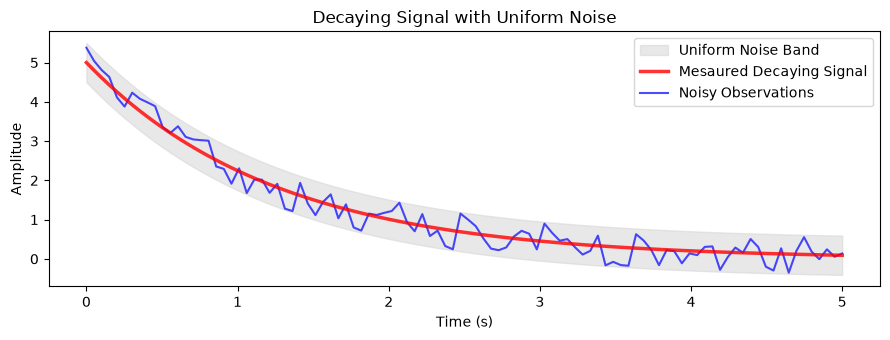

In [30]:
# graphical representation of the decaying signal with uniform noise

plt.figure(figsize=(9, 3.5))

#bounded noise band visualization(shaded envelope)

plt.fill_between(

    x=t_decay, #time array
    y1=y_decay_pure-0.5, #upper bound of the noise band
    y2=y_decay_pure +0.5, #lower bound of the noise band
    color='lightgray', #color of the noise band
    alpha=0.5, #transparency of the noise band
    zorder=1, #layering order of the noise band
    label='Uniform Noise Band' #label for the legend    
)

plt.plot(
    t_decay, #time array
    y_decay, #pure decaying signal array
    color='red', #color of the line
    linewidth=2.5, #width of the line
    zorder=3, #layering order of the line
    label='Mesaured Decaying Signal' ,#label for the legend
    markersize=5,
    alpha=0.8
)

plt.plot(
    t_decay, #time array
    y_decay_noisy, #noisy decaying signal array
    color='blue', #color of the points
    alpha=0.7, #transparency of the points
    zorder=2, #layering order of the points
    label='Noisy Observations', #label for the legend
)

plt.title('Decaying Signal with Uniform Noise')
plt.xlabel('Time (s)')
plt.ylabel('Amplitude')
plt.legend()
plt.tight_layout()
plt.show()

# Polynomial Function + Sparse Outliers (salt & pepper/Impulse Noise )

Cubic polynomial signal with random spikes generated successfully.
Total number of points: 120
Number of outliers added: 9
Outlier indices: [ 53  26  99  95 106  79  19   3  31]
Outlier values: [6.49953858 8.25273845 6.31332461 5.92926018 7.52861718 5.5005004
 6.21712403 0.91281522 7.47530814]
clean data mean : 0.6442577030812325


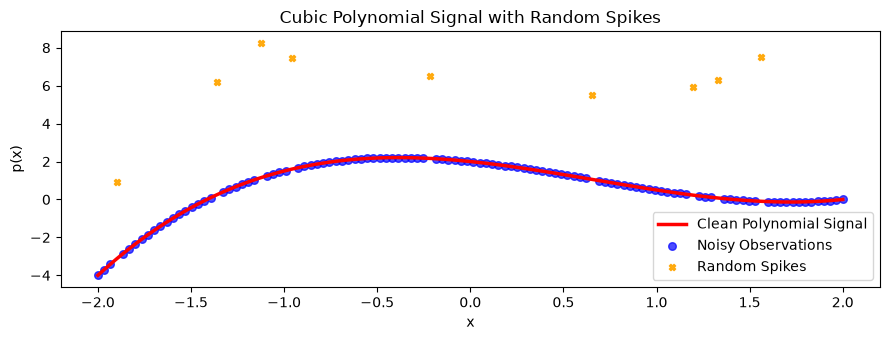

In [31]:
x_poly=np.linspace(
    start =-2, #start time
    stop = 2, #stop time
    num = 120 # number of points
)

# Cubic polynomial function p(x)= 0.5*x^3 - x^2 - x +2 
y_poly_clean = 0.5*x_poly**3 - x_poly**2 - x_poly + 2
y_poly_noisy = y_poly_clean.copy()

# select 8% of indices randomly to add noise

num_outliers = int(0.08 * len(x_poly)) # 8% of the total number of points

outlier_indices = np.random.choice(len(x_poly), size=num_outliers, replace=False)

spikes_magnitude = np.random.uniform(low=4.0, high=8.0, size=num_outliers) # random spikes between 4 and 8

y_poly_noisy[outlier_indices] += spikes_magnitude # add spikes to the selected indices

print("Cubic polynomial signal with random spikes generated successfully.")
print(f"Total number of points: {len(x_poly)}")
print(f"Number of outliers added: {num_outliers}")
print(f"Outlier indices: {outlier_indices}")
print(f"Outlier values: {y_poly_noisy[outlier_indices]}")
print(f"clean data mean : {np.mean(y_poly_clean)}")


plt.figure(figsize=(9, 3.5))
plt.plot(
    x_poly, #x array
    y_poly_clean, #clean polynomial signal array
    color='red', #color of the line
    linewidth=2.5, #width of the line
    zorder=3, #layering order of the line
    label='Clean Polynomial Signal', #label for the legend
)

# uncurrpted points(regular observations)
normal_mask = np.ones_like(y_poly_noisy, dtype=bool) # create a boolean mask for all points
normal_mask[outlier_indices] = False # set the outlier indices to False

plt.scatter(
    x=x_poly[normal_mask], #x array
    y=y_poly_noisy[normal_mask], #noisy polynomial signal array
    color='blue', #color of the points
    alpha=0.7, #transparency of the points
    zorder=2, #layering order of the points
    label='Noisy Observations', #label for the legend
    s=30
)

# Outlier POints (random spikes)
plt.scatter(
    x=x_poly[outlier_indices], #x array
    y=y_poly_noisy[outlier_indices], #noisy polynomial signal array
    color='orange', #color of the points
    alpha=0.9, #transparency of the points
    zorder=2, #layering order of the points
    label='Random Spikes', #label for the legend
    s=20, #size of the points
    marker='X'  #marker style for the outliers
)
plt.title('Cubic Polynomial Signal with Random Spikes')
plt.xlabel('x')
plt.ylabel('p(x)')
plt.legend()
plt.tight_layout()
plt.show()

# multi-Component Composite Signal + Hetroscedastic Noise

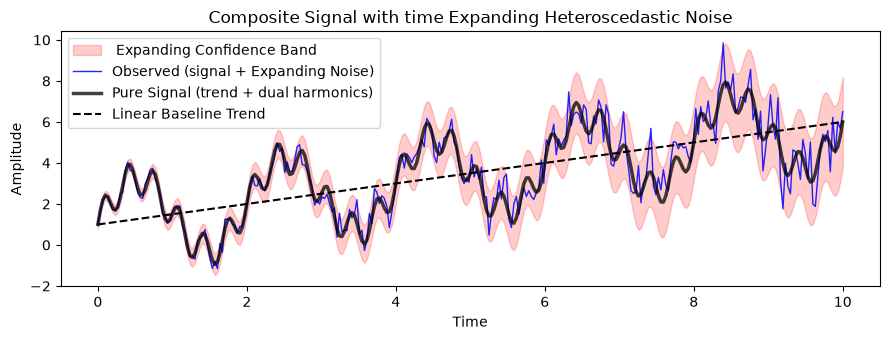

In [36]:
t_comp=np.linspace(
    start =0, #start time
    stop = 10, #stop time
    num = 300 # number of points
)

#Componet 1: Linear Upward trend(m=0.5,c=1.0)
trend =0.5 * t_comp + 1.0

#Componet 2& 3: Dual - frequency harmonics (0.5Hz low frequency and 3 Hz high frequency) 

harmonics = 2.0 *np.sin(2*np.pi*0.5*t_comp) + 0.8 * np.sin(2*np.pi*3*t_comp)

s_pure=trend + harmonics #pure composite signal

sigma_t= 0.1 + 0.1* t_comp

hetero_noise = np.random.normal(
    loc = 0.0,
    scale = 1.0,
    size  = len(t_comp)
) * sigma_t

y_composite = s_pure + hetero_noise

plt.figure(figsize = (9,3.5))

plt.fill_between(
    x=t_comp,
    y1=s_pure - 2* sigma_t,
    y2=s_pure +2 * sigma_t,
    color = 'red',
    alpha = 0.2,
    label =' Expanding Confidence Band'
)

plt.plot(
    t_comp,
    y_composite,
    color='blue',
    linewidth = 1.0,
    alpha = 0.85,
    label='Observed (signal + Expanding Noise)'
)

plt.plot(
    t_comp,
    s_pure,
    color = 'black',
    linewidth=2.5,
    alpha = 0.75,
    label='Pure Signal (trend + dual harmonics)'
)

plt.plot(
    t_comp,
    trend,
    'k--',
    linewidth = 1.5,
    label='Linear Baseline Trend'
)

plt.title("Composite Signal with time Expanding Heteroscedastic Noise")
plt.xlabel("Time")
plt.ylabel("Amplitude")
plt.legend()
plt.tight_layout()
plt.show()